# <font color='darkblue'>*Marina Napoleão - EBAC*</font>
## <font color='darkblue'>Projeto Estatística Aplicada - Efetividade de Duas Estratégias de Ensino</font>

#### ANOTAÇÕES
* <font color='purple'>Unilateral direita → H0: μ_B <= μ_A |     H1: μ_B > μ_A</font>
* <font color='purple'>Unilateral esquerda → H0: μ_B >= μ_A |    H1: μ_B < μ_A</font>
* <font color='purple'> Bicaudal →  H0: μ_B = μ_A |    H1: μ_B ≠ μ_A</font>

*p-valor* com um nível de significância (α, geralmente 0,05):

* <font color='purple'>p ≤ α = Rejeitamos H₀</font>

* <font color='purple'>p > α = Não rejeitamos H₀</font>

* <font color='purple'>|Z| > Z crítico = Rejeitamos H₀ → Diferença significativa.</font>

* <font color='purple'>|Z| ≤ Z crítico = Não rejeitamos H₀ → Diferença não significativa.</font>

----

# **MÓDULO 19**
# Exercício: Estatística Aplicada

**Efetividade de Duas Estratégias de Ensino**

Imagine que uma escola esteja avaliando a eficácia de duas estratégias de ensino de matemática para alunos do ensino médio. Eles querem determinar se há uma diferença significativa no desempenho médio dos alunos entre as duas estratégias.

# **Hipóteses:**

* Hipótese nula (H0): A média das notas dos alunos na estratégia A é igual à média das notas dos alunos na estratégia B.
* Hipótese alternativa (H1): A média das notas na Estratégia B é maior do que a média das notas na Estratégia A.

# **Dados:**

* Amostra da Estratégia A: Notas de 50 alunos que receberam a Estratégia A.
* Amostra da Estratégia B: Notas de 50 alunos que receberam a Estratégia B.

Usaremos um teste Z para comparar as médias das notas entre as duas amostras.

Se o p-valor do teste Z for menor que um nível de significância pré-determinado (por exemplo, α = 0.05), rejeitamos a hipótese nula e concluímos que há uma diferença significativa nas médias das notas entre as duas estratégias de ensino.

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("Seaborn:", sns.__version__)

C:\Users\marina\anaconda3\lib\site-packages\pandas\core\computation\expressions.py:21: UserWarning: Pandas requires version '2.8.4' or newer of 'numexpr' (version '2.8.3' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
C:\Users\marina\anaconda3\lib\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


NumPy: 1.26.4
Pandas: 2.3.2
Seaborn: 0.13.2


In [2]:
from scipy import stats
from scipy.stats import norm

In [3]:
# Definindo médias e desvios padrão para as notas nas duas estratégias
media_estrategia_A = 70
desvio_padrao_estrategia_A = 10

media_estrategia_B = 75
desvio_padrao_estrategia_B = 12

# Gerando as amostras de notas para cada estratégia de ensino da nossa base
np.random.seed(0)  # Para garantir a reprodutibilidade dos resultados
amostra_estrategia_A = np.random.normal(loc=media_estrategia_A, scale=desvio_padrao_estrategia_A, size=50)
amostra_estrategia_B = np.random.normal(loc=media_estrategia_B, scale=desvio_padrao_estrategia_B, size=50)

print("Notas da Estratégia A:", amostra_estrategia_A[:5])
print("Notas da Estratégia B:", amostra_estrategia_B[:5])

Notas da Estratégia A: [87.64052346 74.00157208 79.78737984 92.40893199 88.6755799 ]
Notas da Estratégia B: [64.25440127 79.64282997 68.87033835 60.83241379 74.66181326]


Os dados são criados a seguir:

# 1) De acordo com as informações analisadas o nosso teste é unilateral á direita, esquerda ou bicaudal? Justifique.




In [4]:
mean_A = amostra_estrategia_A.mean()
mean_B = amostra_estrategia_B.mean()
print('Média estrategia_A:', mean_A, '\n', 'Média estrategia_B:', mean_B, '\n')

if mean_B > mean_A:
    print('Unilateral direita')
elif mean_B < mean_A:
    print('Unilateral esquerda')
else:
    print('Bicaudal')

Média estrategia_A: 71.40559272313098 
 Média estrategia_B: 74.74868110507046 

Unilateral direita


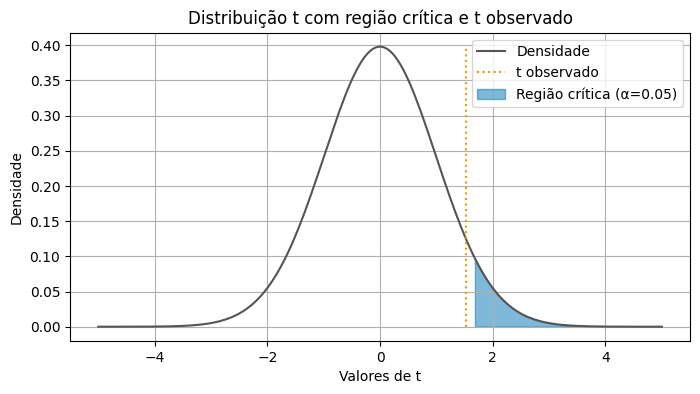

In [5]:
cores = ['#0072B2', '#E69F00', '#009E73', '#F0E442', '#CC79A7', '#555555']

#Gráfico para representar que o teste é unilateral direita
n_A = len(amostra_estrategia_A)
n_B = len(amostra_estrategia_B)
std_A = amostra_estrategia_A.std(ddof=1)
std_B = amostra_estrategia_B.std(ddof=1)

t_statistic = (mean_B - mean_A) / np.sqrt(std_A**2/n_A + std_B**2/n_B)
df = n_A + n_B - 2

#limite critico
t_critico = stats.t.ppf(0.95, df)

#Eixo central da media do t
x = np.linspace(-5, 5, 200)
y = stats.t.pdf(x, df)

fig, ax = plt.subplots(figsize=(8,4))

# Curva de densidade
ax.plot(x, y, label = 'Densidade', color = cores[5])

# Linha do t observado
ax.vlines(t_statistic, 0, y.max(), colors = cores[1], linestyles='dotted', label='t observado')

# Área crítica para teste unilateral à direita
ax.fill_between(x, y, where=(x >= t_critico), color = cores[0], alpha = 0.5, label = 'Região crítica (α=0.05)')

plt.legend()
plt.xlabel('Valores de t')
plt.ylabel('Densidade')
plt.title('Distribuição t com região crítica e t observado')
plt.grid(True)
plt.show()



* <font color='blue'>Podemos notar que o 't observado' é de aproximadamente 1.5 e não se encontra na região crítica. A região crítica está presente somente no lado direito do gráfico e há uma diferença de 3.34 entre as médias A e B.</font>

-------

# 2) Calcule as médias para as duas amostragens e as variâncias. Quais insights você pode retirar comparando os dados?

In [6]:
#Seu código aqui
# Calcular as médias amostrais
media_estrategia_A = amostra_estrategia_A.mean()
media_estrategia_B = amostra_estrategia_B.mean()
print('Média_A:', media_estrategia_A,'\n', 'Média_B:', media_estrategia_B, '\n')

# Calcular as variâncias amostrais
var_estrategia_A = amostra_estrategia_A.var(ddof = 1)
var_estrategia_B = amostra_estrategia_B.var(ddof = 1)
print('Variância_A:', var_estrategia_A, '\n', 'Variância_B:', var_estrategia_B)

Média_A: 71.40559272313098 
 Média_B: 74.74868110507046 

Variância_A: 129.2654943565623 
 Variância_B: 110.4700206552835


In [7]:
#Seu código aqui
n = 50
taxa_estrategia_A = 0.71 
taxa_estrategia_B = 0.74

np.random.seed(0)  # Para garantir a reprodutibilidade
grupo_estrategia_A = np.random.binomial(n = 1, p = taxa_estrategia_A, size = n)
grupo_estrategia_B = np.random.binomial(n = 1, p = taxa_estrategia_B, size = n)

print("Grupo da estrategia_A:", grupo_estrategia_A, '\n')
print("Grupo da estrategia_B:", grupo_estrategia_B)

Grupo da estrategia_A: [1 0 1 1 1 1 1 0 0 1 0 1 1 0 1 1 1 0 0 0 0 0 1 0 1 1 1 0 1 1 1 0 1 1 1 1 1
 1 0 1 1 1 1 1 1 1 1 1 1 1] 

Grupo da estrategia_B: [1 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 0 1 0 1 0 1 0 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 0 1 1 1 1 1 1 1 1 0 1]


* <font color='blue'>A estratégia_B apresenta uma média maior e também notas menos dispersas. Apesar da diferença positiva entre as médias, 3.34, o valor não é significativo, pois é menos de 5%.</font>

-----

# 3) Imprima os resultados da estatística do teste Z, p value e indique se rejeitaremos ou não a hipótese nula. Justifique sua resposta.

In [8]:
# Tamanho das amostras
n = 50

# Calcular a estatística de teste Z com a formula:
z_statistic = (mean_B - mean_A) / np.sqrt((desvio_padrao_estrategia_A**2/n) + (desvio_padrao_estrategia_B**2/n))

# Calcular o p-valor (teste unilateral)
p_valor_unilateral = 1 - stats.norm.cdf(abs(z_statistic))

# Calcular o p-valor (teste bilateral)
p_valor_bilateral = 2 * (1 - stats.norm.cdf(abs(z_statistic)))


# Imprimir os resultados
print("Estatística de teste Z:", z_statistic, '\n')
print("p-valor unilateral:", p_valor_unilateral, '\n')
print("p-valor bilateral:", p_valor_bilateral, '\n')

# Comparar o p-valor com o nível de significância
nivel_significancia = 0.05

if p_valor_unilateral < nivel_significancia:
    print("Rejeitamos a hipótese nula: há uma diferença significativa entre as médias das duas estrategias.")
else:
    print("Não rejeitamos a hipótese nula: não há evidências suficientes para concluir que há uma diferença significativa entre as duas estrategias.")

Estatística de teste Z: 1.513345003724835 

p-valor unilateral: 0.0650960234112008 

p-valor bilateral: 0.1301920468224016 

Não rejeitamos a hipótese nula: não há evidências suficientes para concluir que há uma diferença significativa entre as duas estrategias.


* <font color='blue'>O valor Z = 1.513 nos indica o quanto os desvios-padrão da diferença entre as estratégias A e B estão distantes de 0. Podemos observar que a estratégia_B dispõe de ter a média maior que a estratégia_A, o que pode representar uma tendência. Porém, o valor Z não fornece evidência estatística suficiente para rejeitar a hipótese nula (H0). Com base nisso, não podemos afirmar que uma estratégia é melhor que a outra.</font>


* <font color='blue'>Apesar de o P-valor unilateral ser maior que o nível de significância, 0.065 > 0.05, não rejeitamos a hipótese nula (H0). Já o P-valor bilateral tem um valor ainda maior, reforçando a ausência de evidências estatísticas significativas de diferença.</font>

------

# 4) Para finalizar monte o gráfico da distribuição da estatística do nosso teste Z e explique o que pode ser observado através dele.

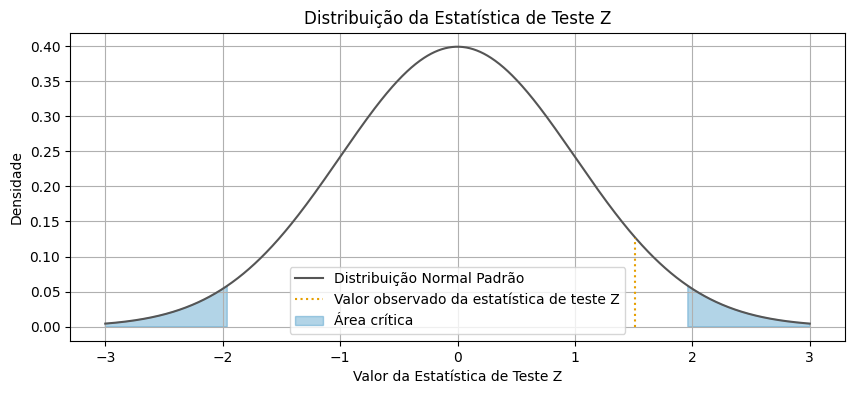

In [9]:
cores = ['#0072B2', '#E69F00', '#009E73', '#F0E442', '#CC79A7', '#555555']

#Seu código aqui
fig, ax = plt.subplots(figsize=(10, 4))

# Valores de X e Y para plotar a distribuição
x = np.linspace(-3, 3, 1000)
y = stats.norm.pdf(x, 0, 1)


# Plotando a distribuição normal padrão
ax.plot(x, y, label='Distribuição Normal Padrão', color = cores[5])

# Marcação do valor observado da estatística do teste
ax.vlines(x=[z_statistic], ymin=0, ymax=stats.norm.pdf(z_statistic, 0, 1),
          colors= cores[1], linestyles='dotted', label='Valor observado da estatística de teste Z')

# Área crítica
critical_region = stats.norm.ppf(0.025), stats.norm.ppf(0.975)
ax.fill_between(x, y, where=(x < critical_region[0]) | (x > critical_region[1]), color= cores[0], alpha=0.3, label='Área crítica')


plt.legend()
plt.xlabel('Valor da Estatística de Teste Z')
plt.ylabel('Densidade')
plt.title('Distribuição da Estatística de Teste Z')
plt.grid(True)

plt.show()

* <font color='blue'>O gráfico nos ajuda a visualizar melhor onde o valor da  estatística de teste se encontra, tornando mais clara a motivação das decisões tomadas.</font>


* <font color='blue'>As áreas sombreadas representam as regiões críticas de rejeição da hipótese nula (H0) para um teste bilateral com o nível de significância (α = 0.05).</font>


* <font color='blue'>A linha tracejada indica o valor observado da estatística Z = 1.51, que está fora da área crítica. Por isso não rejeitamos a hipótese nula (H0).</font>

---------